# Chronos-2 Zero-Shot Forecasting with Covariates & Cross-Learning

Notebook này được điều chỉnh dựa trên Quickstart của Amazon, sử dụng dữ liệu mới (`features_train.csv` & `features_test.csv`). Chúng ta sẽ sử dụng:
1. **Past Covariates**: `vix_dev`, `macd`, `risk_off_composite`, `ibor_rate`... để Chronos học lịch sử.
2. **Known Future Covariates**: Các biến kiểu thời gian (ngày, tháng, quý) mà ta luôn biết trước ở tương lai.
3. **Cross-Learning**: Học chéo đa biến (multivariate) từ tập context của TẤT CẢ các mã cổ phiếu cùng lúc.

In [12]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from chronos import Chronos2Pipeline

import warnings
warnings.filterwarnings("ignore")

# Cấu hình
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
ROOT_DIR   = Path.cwd().parent.parent
TRAIN_PATH = ROOT_DIR / "data" / "processed" / "v2" / "features_train.csv"
TEST_PATH  = ROOT_DIR / "data" / "processed" / "v2" / "features_test.csv"

In [13]:
# ========== 1. LOAD DỮ LIỆU & RESAMPLE (TRÁNH LỖI HỎNG INFER FREQ) ==========
print("Đang load features_train và features_test...")
df_train = pd.read_csv(TRAIN_PATH, parse_dates=["Date"])
df_test  = pd.read_csv(TEST_PATH, parse_dates=["Date"])

# Danh sách past covariates từ features của bạn
past_covariates = [
    "vnm_ret", "vix_dev", "risk_off_composite", "hsi_vol_20",
    "macd", "vix", "hsi_ret_1d", "pmi_norm", "ibor_rate",
    "ibor_event", "usdvnd_dev"
]
target_col = "Close"
id_column = "ticker"
time_column = "Date"

# Hợp nhất để tạo chuỗi liền mạch
df_all = pd.concat([df_train, df_test], ignore_index=True)

# Để làm Known Future Covariates, ta trích xuất calendar features:
df_all["day_of_week"] = df_all[time_column].dt.dayofweek
df_all["quarter"] = df_all[time_column].dt.quarter
df_all["month"] = df_all[time_column].dt.month
known_future_covariates = ["day_of_week", "quarter", "month"]

# Resample sang Business Days để Chronos-2 đọc được tần số (Frequency inference)
print("Đang Resample sang Business Days (B) để điền đầy các ngày nghỉ...")
dfs = []
for ticker_id, group in df_all.groupby(id_column):
    g_resampled = group.set_index(time_column).resample('B').ffill()
    g_resampled[id_column] = ticker_id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)

# Lọc chỉ lấy các cột cần thiết cho model input
cols_to_keep = [id_column, time_column, target_col] + past_covariates + known_future_covariates
df_ticker = df_ticker[cols_to_keep]

print(f"Tổng dữ liệu: {len(df_ticker)} dòng trên {df_ticker[id_column].nunique()} tickers.")

Đang load features_train và features_test...
Đang Resample sang Business Days (B) để điền đầy các ngày nghỉ...
Tổng dữ liệu: 50205 dòng trên 15 tickers.


In [14]:
# ========== 2. THIẾT LẬP SLIDING WINDOW (ROLLING 1-STEP AHEAD) ==========
# Thay vì dự báo một lèo 30 ngày (sẽ ra đường ngang), ta dùng sliding window
# Mỗi bước lấy LOOKBACK ngày trong quá khứ để dự đoán đúng 1 ngày tiếp theo.

LOOKBACK = 20          # Lấy 20 phiên lịch sử
TEST_DAYS = 30         # Backtest trên 30 ngày cuối cùng

# Xác định danh sách các ngày test
all_dates = sorted(df_ticker[time_column].unique())
test_dates = all_dates[-TEST_DAYS:]

print(f"Sẽ chạy Rolling Forecast: Lookback={LOOKBACK} days -> Predict=1 day.")
print(f"Thực hiện trượt trên {TEST_DAYS} ngày cuối cùng: từ {test_dates[0].date()} đến {test_dates[-1].date()}")


Sẽ chạy Rolling Forecast: Lookback=20 days -> Predict=1 day.
Thực hiện trượt trên 30 ngày cuối cùng: từ 2025-11-19 đến 2025-12-30


In [15]:
# ========== 3. TẢI CHRONOS-2 ==========
print("Đang load amazon/chronos-2...")
device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map=device,
    torch_dtype=torch.bfloat16 if device == "cuda" else torch.float32,
)
print("Load hoàn tất!")

Đang load amazon/chronos-2...
Load hoàn tất!


Bắt đầu chạy Sliding Window Inference...
  Đang chạy bước 1/30 (Target: 2025-11-19)...
  Đang chạy bước 5/30 (Target: 2025-11-25)...
  Đang chạy bước 10/30 (Target: 2025-12-02)...
  Đang chạy bước 15/30 (Target: 2025-12-09)...
  Đang chạy bước 20/30 (Target: 2025-12-16)...
  Đang chạy bước 25/30 (Target: 2025-12-23)...
  Đang chạy bước 30/30 (Target: 2025-12-30)...
Inference hoàn tất và VƯỢT QUA các bài kiểm tra rò rỉ dữ liệu (No Data Leak detected in pipeline)!


,ticker,Date,target_name,predictions,0.1,0.5,0.9
0,ACB,2025-11-19,Close,25.147198,24.865501,25.147198,25.492023
1,BVH,2025-11-19,Close,54.388947,52.746078,54.388947,55.832729
2,CTG,2025-11-19,Close,34.186821,33.464714,34.186821,34.920818
3,FPT,2025-11-19,Close,99.106285,96.000275,99.106285,102.244194
4,GAS,2025-11-19,Close,62.405102,61.082458,62.405102,63.602337


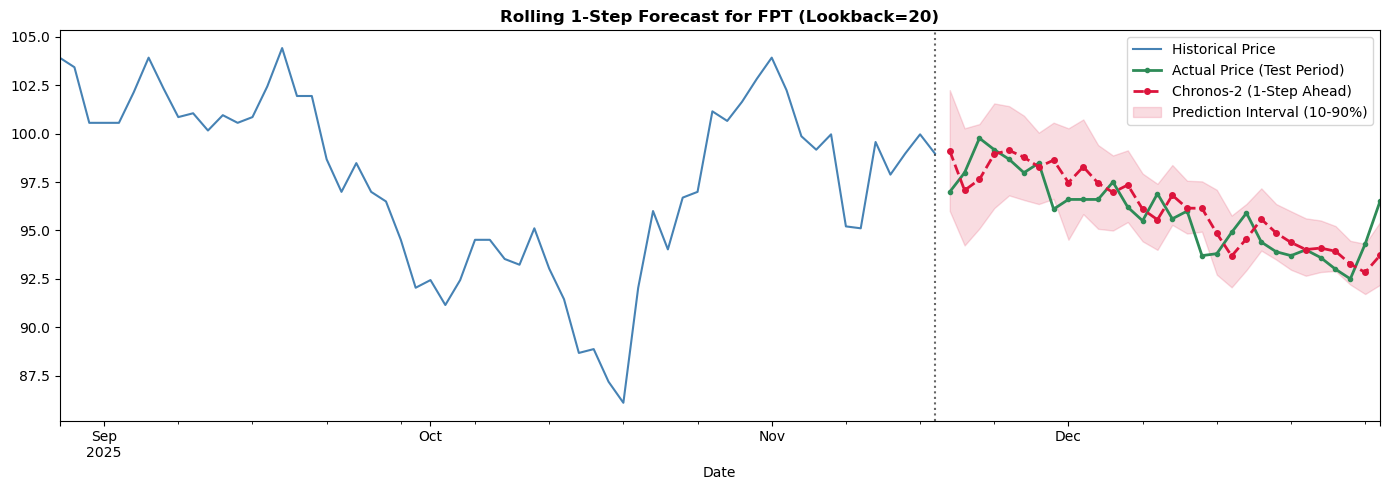

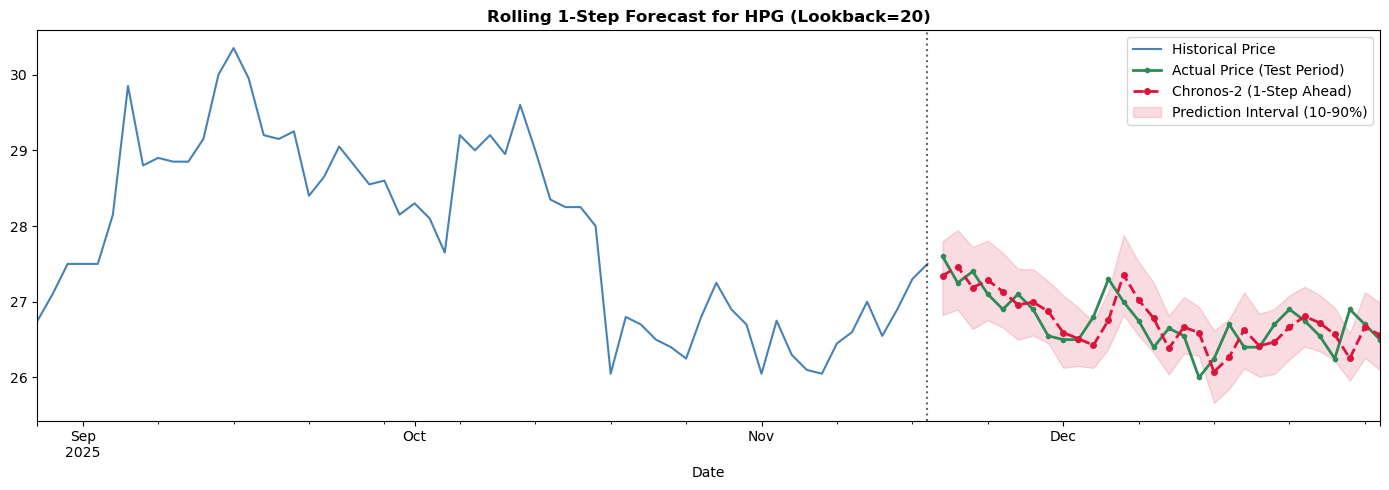

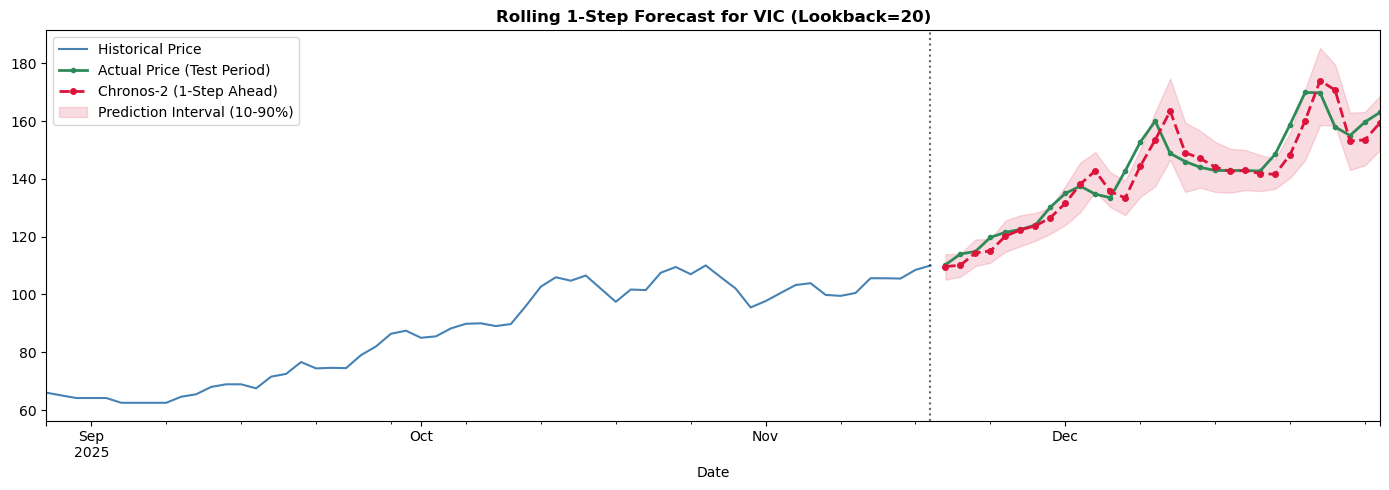

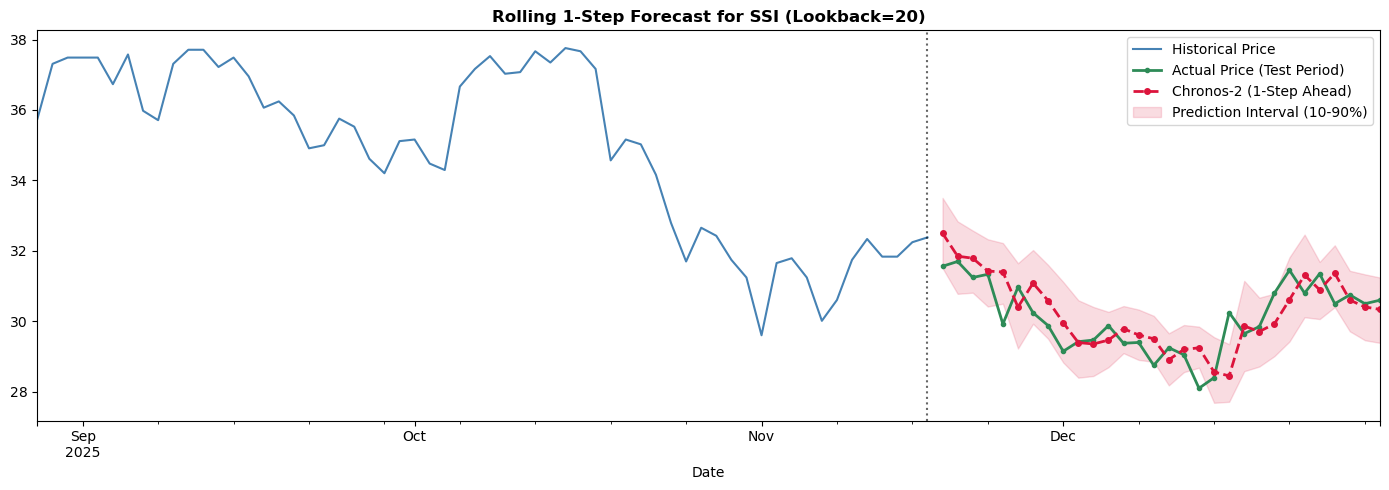

In [17]:
# ========== 5. TRỰC QUAN HÓA KẾT QUẢ ĐỐI CHIẾU (1-STEP AHEAD) ==========
def plot_rolling_forecast(ticker_id, target_col="Close", show_history_len=60):
    # Lấy giá thực tế của test period và 1 đoạn lịch sử để nối biểu đồ
    test_start_date = test_dates[0]
    
    # 1. Lọc giá lịch sử (để vẽ đường bối cảnh đằng trước)
    ts_hist = df_ticker[(df_ticker[id_column] == ticker_id) & (df_ticker[time_column] < test_start_date)]
    ts_hist = ts_hist.tail(show_history_len).set_index(time_column)[target_col]
    
    # 2. Lọc giá thực tế trong giai đoạn test
    ts_actual = df_ticker[(df_ticker[id_column] == ticker_id) & (df_ticker[time_column].isin(test_dates))]
    ts_actual = ts_actual.set_index(time_column)[target_col]
    
    # 3. Lọc số liệu dự đoán
    ts_pred = pred_df[(pred_df[id_column] == ticker_id) & (pred_df["target_name"] == target_col)]
    ts_pred = ts_pred.set_index(time_column)[["0.1", "predictions", "0.9"]]
    
    # Ghép điểm cuối của history vào để đồ thị không bị đứt đoạn
    last_hist_val = pd.Series([ts_hist.iloc[-1]], index=[ts_hist.index[-1]])
    ts_actual_plot = pd.concat([last_hist_val, ts_actual])
    
    # Vẽ
    fig, ax = plt.subplots(figsize=(14, 5))
    
    ts_hist.plot(ax=ax, label="Historical Price", color="steelblue", linewidth=1.5)
    ts_actual.plot(ax=ax, label="Actual Price (Test Period)", color="seagreen", marker=".", linewidth=2)
    ts_pred["predictions"].plot(ax=ax, label="Chronos-2 (1-Step Ahead)", color="crimson", linewidth=2, linestyle="--", marker="o", markersize=4)
    
    ax.fill_between(
        ts_pred.index, ts_pred["0.1"], ts_pred["0.9"],
        color="crimson", alpha=0.15, label="Prediction Interval (10-90%)"
    )
    
    ax.axvline(x=ts_hist.index[-1], color="black", linestyle=":", alpha=0.6)
    ax.set_title(f"Rolling 1-Step Forecast for {ticker_id} (Lookback=20)", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.show()

# In thử dự báo cho 3 mã ngẫu nhiên: FPT, HPG, VIC
for tk in ["FPT", "HPG", "VIC", "SSI"]:
    plot_rolling_forecast(tk)
